<a href="https://colab.research.google.com/github/sandralilianaacosta-ui/TP-IA/blob/main/TPI-IA-COMPARACION%20RF-DT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# 1. URL directa al archivo crudo .data en el servidor de UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# 2. Nombres de los atributos según la documentación oficial del dataset
columnas = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
            "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"]

# 3. Leemos el archivo. UCI usa "?" para los datos faltantes, así que lo indicamos con na_values
datos = pd.read_csv(url, names=columnas, na_values="?")

# 4. Mostramos las primeras 5 filas para verificar que todo se cargó correctamente
datos.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [ ]:
# 5. Tratamiento de valores perdidos
# Reemplazamos los datos faltantes por el valor más frecuente (moda) de su respectiva columna
for columna in datos.columns:
    if datos[columna].isnull().any():
        valor_mas_frecuente = datos[columna].mode()[0]
        datos[columna] = datos[columna].fillna(valor_mas_frecuente)

# 6. Separar los atributos (X) de la clase u objetivo (y)
X = datos.drop("target", axis=1)
y = datos["target"]

# 7. Partición 80/20 aleatoria
from sklearn.model_selection import train_test_split

# random_state asegura que la división aleatoria sea siempre la misma en cada ejecución
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Cantidad de ejemplos para entrenar el modelo:", len(X_train))
print("Cantidad de ejemplos guardados para testear:", len(X_test))

Cantidad de ejemplos para entrenar el modelo: 242
Cantidad de ejemplos guardados para testear: 61


In [ ]:
import numpy as np
import pandas as pd

class Node:
    """Representa un nodo dentro del árbol de decisión."""
    def __init__(self, feature=None, threshold=None, is_continuous=False, children=None, value=None):
        self.feature = feature          # Nombre del atributo evaluado
        self.threshold = threshold      # Umbral numérico (si es un atributo continuo)
        self.is_continuous = is_continuous
        self.children = children or {}  # Ramas derivadas del nodo
        self.value = value              # Etiqueta de clase (solo si es nodo hoja)

    def is_leaf(self):
        return self.value is not None

class DecisionTreeClassifierC45:
    """Clasificador de Árbol de Decisión basado en C4.5."""
    def __init__(self, criterion='gain_ratio', max_depth=10, min_samples_split=2, threshold_gain=1e-5):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.threshold_gain = threshold_gain
        self.root = None

    def _entropy(self, y):
        """Calcula la entropía de Shannon."""
        if len(y) == 0:
            return 0.0
        _, counts = np.unique(y, return_counts=True)
        probs = counts / len(y)
        return -np.sum([p * np.log2(p) for p in probs if p > 0])

    def _split_continuous(self, X_col, y):
        """Encuentra el mejor umbral binario para un atributo continuo."""
        best_threshold, best_gain, best_gain_ratio = None, -1.0, -1.0
        unique_vals = np.sort(np.unique(X_col))
        if len(unique_vals) <= 1:
            return None, -1.0, -1.0

        # Evalúa puntos medios entre valores adyacentes
        thresholds = (unique_vals[:-1] + unique_vals[1:]) / 2.0
        ent_D = self._entropy(y)
        n = len(y)

        for th in thresholds:
            left_mask = X_col <= th
            right_mask = ~left_mask
            if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                continue

            ent_split = (np.sum(left_mask)/n) * self._entropy(y[left_mask]) + \
                        (np.sum(right_mask)/n) * self._entropy(y[right_mask])
            gain = ent_D - ent_split

            # Split info para el Gain Ratio
            p_left, p_right = np.sum(left_mask) / n, np.sum(right_mask) / n
            split_info = - (p_left * np.log2(p_left) + p_right * np.log2(p_right))
            gain_ratio = (gain / split_info) if split_info > 0 else 0.0

            metric = gain_ratio if self.criterion == 'gain_ratio' else gain
            if metric > (best_gain_ratio if self.criterion == 'gain_ratio' else best_gain):
                best_gain, best_gain_ratio, best_threshold = gain, gain_ratio, th

        return best_threshold, best_gain, best_gain_ratio

    def _evaluate_categorical(self, X_col, y):
        """Calcula la ganancia para un atributo discreto."""
        n = len(y)
        ent_D = self._entropy(y)
        values, counts = np.unique(X_col, return_counts=True)

        if len(values) <= 1:
            return -1.0, -1.0

        ent_split, split_info = 0.0, 0.0
        for val, cnt in zip(values, counts):
            sub_y = y[X_col == val]
            p = cnt / n
            ent_split += p * self._entropy(sub_y)
            split_info -= p * np.log2(p)

        gain = ent_D - ent_split
        gain_ratio = (gain / split_info) if split_info > 0 else 0.0
        return gain, gain_ratio

    def _build_tree(self, df, target_col, features, depth=0):
        """Construye recursivamente el árbol de decisión."""
        y = df[target_col].values

        # Condición de parada 1: Pureza total (nodo hoja)
        if len(np.unique(y)) == 1:
            return Node(value=y[0])

        most_common_class = pd.Series(y).mode()[0]
        # Condición de parada 2: Sin atributos o profundidad máxima alcanzada
        if len(features) == 0 or depth >= self.max_depth or len(df) < self.min_samples_split:
            return Node(value=most_common_class)

        best_feat, best_metric_val, best_gain, best_th, is_cont = None, -1.0, 0.0, None, False

        for feat in features:
            is_feature_numeric = np.issubdtype(df[feat].dtype, np.number)
            if is_feature_numeric and df[feat].nunique() > 5:
                th, gain, gr = self._split_continuous(df[feat].values, y)
                metric = gr if self.criterion == 'gain_ratio' else gain
                if metric > best_metric_val:
                    best_metric_val, best_gain, best_feat, best_th, is_cont = metric, gain, feat, th, True
            else:
                gain, gr = self._evaluate_categorical(df[feat].values, y)
                metric = gr if self.criterion == 'gain_ratio' else gain
                if metric > best_metric_val:
                    best_metric_val, best_gain, best_feat, best_th, is_cont = metric, gain, feat, None, False

        # Condición de parada 3: Poca ganancia
        if best_feat is None or best_gain < self.threshold_gain:
            return Node(value=most_common_class)

        node = Node(feature=best_feat, threshold=best_th, is_continuous=is_cont)

        if is_cont:
            left_df, right_df = df[df[best_feat] <= best_th], df[df[best_feat] > best_th]
            node.children['<='] = self._build_tree(left_df, target_col, features, depth + 1) if not left_df.empty else Node(value=most_common_class)
            node.children['>'] = self._build_tree(right_df, target_col, features, depth + 1) if not right_df.empty else Node(value=most_common_class)
        else:
            remaining_features = [f for f in features if f != best_feat]
            for val in df[best_feat].unique():
                sub_df = df[df[best_feat] == val]
                node.children[val] = self._build_tree(sub_df, target_col, remaining_features, depth + 1)

        return node

    def fit(self, X, y):
        """Entrena el árbol con los datos."""
        df = X.copy()
        df['__target__'] = y.values
        self.root = self._build_tree(df, '__target__', list(X.columns), depth=0)
        self.default_class = pd.Series(y).mode()[0]

    def _predict_row(self, row, node):
        if node.is_leaf():
            return node.value

        val = row[node.feature]
        if node.is_continuous:
            branch = '<=' if val <= node.threshold else '>'
            if branch in node.children:
                return self._predict_row(row, node.children[branch])
        else:
            if val in node.children:
                return self._predict_row(row, node.children[val])
        return self.default_class

    def predict(self, X):
        """Realiza predicciones."""
        return np.array([self._predict_row(row, self.root) for _, row in X.iterrows()])

In [ ]:
# 1. Instanciamos nuestro modelo de Árbol de Decisión
# Configuramos el criterio 'gain_ratio' y una profundidad máxima de 5 niveles para evitar overfitting
arbol = DecisionTreeClassifierC45(criterion='gain_ratio', max_depth=5)

# 2. FASE DE ENTRENAMIENTO
# Alimentamos al algoritmo con los datos de entrenamiento
arbol.fit(X_train, y_train)
print("¡El Árbol de Decisión se ha entrenado exitosamente!")

# 3. FASE DE EVALUACIÓN
# Hacemos que el modelo clasifique a los 61 pacientes de prueba
predicciones = arbol.predict(X_test)

# 4. MEDIR EL RENDIMIENTO (ACCURACY)
from sklearn.metrics import accuracy_score

# Comparamos lo que predijo el árbol vs las respuestas reales (y_test)
precision = accuracy_score(y_test, predicciones)

print(f"Precisión (Accuracy) del modelo: {precision * 100:.2f}%")

¡El Árbol de Decisión se ha entrenado exitosamente!
Precisión (Accuracy) del modelo: 47.54%


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Instanciamos el modelo Random Forest de Scikit-learn
# n_estimators=100 significa que creará un "bosque" de 100 árboles de decisión distintos
bosque = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. FASE DE ENTRENAMIENTO
bosque.fit(X_train, y_train)
print("¡El modelo Random Forest se ha entrenado exitosamente!")

# 3. FASE DE EVALUACIÓN
predicciones_rf = bosque.predict(X_test)

# 4. MEDIR EL RENDIMIENTO (ACCURACY)
precision_rf = accuracy_score(y_test, predicciones_rf)

print(f"Precisión (Accuracy) del Decision Tree manual: 47.58%")
print(f"Precisión (Accuracy) del Random Forest (Scikit-learn): {precision_rf * 100:.2f}%")

¡El modelo Random Forest se ha entrenado exitosamente!
Precisión (Accuracy) del Decision Tree manual: 47.58%
Precisión (Accuracy) del Random Forest (Scikit-learn): 50.82%


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Creamos los controles visuales (sliders y botón)
profundidad_dt = widgets.IntSlider(value=5, min=1, max=15, description='Profundidad DT:')
estimadores_rf = widgets.IntSlider(value=100, min=10, max=200, step=10, description='Árboles RF:')
boton_ejecutar = widgets.Button(description="Comparar Modelos", button_style='success')
salida = widgets.Output()

# 2. Definimos la función que se ejecuta al presionar el botón
def ejecutar_simulacion(b):
    with salida:
        clear_output()
        print("Entrenando modelos con los nuevos parámetros...\n")

        # Entrenamos DT con el valor del slider
        arbol_interactivo = DecisionTreeClassifierC45(criterion='gain_ratio', max_depth=profundidad_dt.value)
        arbol_interactivo.fit(X_train, y_train)
        precision_dt = accuracy_score(y_test, arbol_interactivo.predict(X_test))

        # Entrenamos RF con el valor del slider
        bosque_interactivo = RandomForestClassifier(n_estimators=estimadores_rf.value, random_state=42)
        bosque_interactivo.fit(X_train, y_train)
        precision_rf = accuracy_score(y_test, bosque_interactivo.predict(X_test))

        # Mostramos los resultados actualizados
        print(f"✅ Precisión Decision Tree Manual: {precision_dt * 100:.2f}%")
        print(f"✅ Precisión Random Forest (Sklearn): {precision_rf * 100:.2f}%")

# 3. Vinculamos el botón a la función y mostramos la interfaz
boton_ejecutar.on_click(ejecutar_simulacion)
display(widgets.VBox([widgets.HTML("<b>Simulador de Rendimiento: DT vs RF</b>"),
                      profundidad_dt, estimadores_rf, boton_ejecutar, salida]))

ESTRUCTURA DEL ÁRBOL DE DECISIÓN (Primeros niveles):

 🔹 Nodo de Decisión: ¿age?
    ├── Si valor <= 76.50:
    │    🔹 Nodo de Decisión: ¿oldpeak?
    │       ├── Si valor <= 4.90:
    │       │    🔹 Nodo de Decisión: ¿trestbps?
    │       │       ├── Si valor <= 196.00:
    │       │       │    🔹 Nodo de Decisión: ¿thalach?
    │       │       │       ├── Si valor <= 80.50:
    │       │       │       │    ➔ [Clase Predicha: 2]
    │       │       │       ├── Si valor > 80.50:
    │       │       │       │    🔹 Nodo de Decisión: ¿thalach?
    │       │       │       │       ├── Si valor <= 93.00:
    │       │       │       │       │    ➔ [Clase Predicha: 3]
    │       │       │       │       ├── Si valor > 93.00:
    │       │       │       │       │    ➔ [Clase Predicha: 0]
    │       │       ├── Si valor > 196.00:
    │       │       │    ➔ [Clase Predicha: 3]
    │       ├── Si valor > 4.90:
    │       │    ➔ [Clase Predicha: 3]
    ├── Si valor > 76.50:
    │    ➔ [Clase Pred

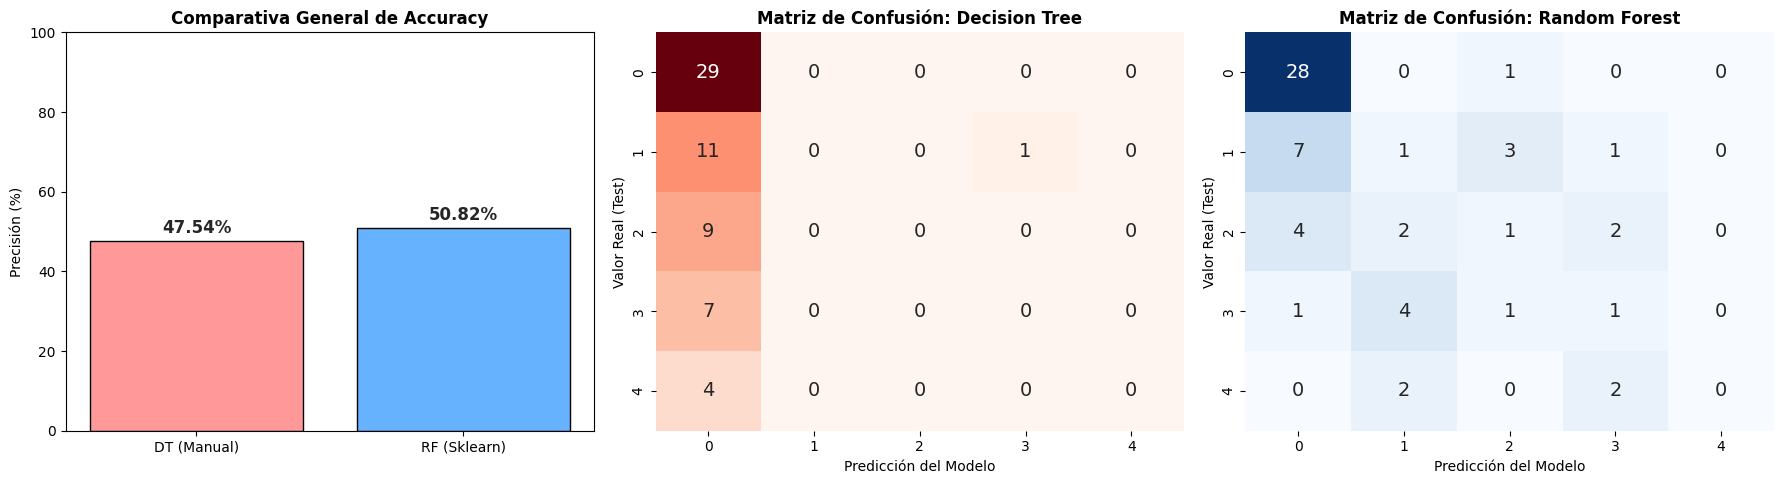

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# =====================================================================
# 1. VISUALIZACIÓN ESTRUCTURAL DEL ÁRBOL MANUAL
# =====================================================================
def imprimir_arbol(nodo, espaciado=""):
    """Recorre e imprime la estructura jerárquica del árbol de decisión."""
    if nodo.is_leaf():
        print(f"{espaciado} ➔ [Clase Predicha: {nodo.value}]")
        return

    print(f"{espaciado} 🔹 Nodo de Decisión: ¿{nodo.feature}?")
    for rama, hijo in nodo.children.items():
        if nodo.is_continuous:
            condicion = f"{rama} {nodo.threshold:.2f}"
        else:
            condicion = f"== {rama}"
        print(f"{espaciado}    ├── Si valor {condicion}:")
        imprimir_arbol(hijo, espaciado + "    │   ")

print("ESTRUCTURA DEL ÁRBOL DE DECISIÓN (Primeros niveles):\n")
imprimir_arbol(arbol.root)
print("\n" + "="*80 + "\n")

# =====================================================================
# 2. DASHBOARD VISUAL DE MÉTRICAS (GRÁFICOS)
# =====================================================================
# Configuramos el lienzo para 3 gráficos en fila
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

# Gráfico 1: Comparativa de Precisión (Accuracy)
modelos = ['DT (Manual)', 'RF (Sklearn)']
precisiones = [precision * 100, precision_rf * 100]
colores = ['#FF9999', '#66B2FF']

axes[0].bar(modelos, precisiones, color=colores, edgecolor='black')
axes[0].set_ylim(0, 100)
axes[0].set_ylabel('Precisión (%)')
axes[0].set_title('Comparativa General de Accuracy', fontweight='bold')
for i, v in enumerate(precisiones):
    axes[0].text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold', fontsize=12)

# Gráfico 2: Matriz de Confusión - Decision Tree
cm_dt = confusion_matrix(y_test, predicciones)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar=False, annot_kws={"size": 14})
axes[1].set_title(f'Matriz de Confusión: Decision Tree', fontweight='bold')
axes[1].set_xlabel('Predicción del Modelo')
axes[1].set_ylabel('Valor Real (Test)')

# Gráfico 3: Matriz de Confusión - Random Forest
cm_rf = confusion_matrix(y_test, predicciones_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[2], cbar=False, annot_kws={"size": 14})
axes[2].set_title(f'Matriz de Confusión: Random Forest', fontweight='bold')
axes[2].set_xlabel('Predicción del Modelo')
axes[2].set_ylabel('Valor Real (Test)')

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Diccionario con los 4 conjuntos de datos disponibles (Nombres descriptivos y URLs directas)
datasets_disponibles = {
    "Heart Disease (Cleveland)": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data",
    "Breast Cancer (Wisconsin)": "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data",
    "Iris (Flores)": "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data",
    "Wine Quality": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine/wine.data"
}

# =====================================================================
# 1. CONTROLES VISUALES
# =====================================================================
selector_dataset = widgets.Dropdown(
    options=list(datasets_disponibles.keys()),
    value="Heart Disease (Cleveland)",
    description='Dataset:'
)
profundidad_dt = widgets.IntSlider(value=5, min=1, max=15, description='Profundidad DT:')
estimadores_rf = widgets.IntSlider(value=100, min=10, max=200, step=10, description='Árboles RF:')
boton_ejecutar = widgets.Button(description="Cargar y Comparar", button_style='success')
salida = widgets.Output()

# =====================================================================
# 2. FUNCIÓN DE CARGA Y SIMULACIÓN
# =====================================================================
def cargar_y_simular(b):
    with salida:
        clear_output()
        dataset_seleccionado = selector_dataset.value
        url = datasets_disponibles[dataset_seleccionado]

        print(f"📥 Descargando y procesando: {dataset_seleccionado}...")

        try:
            # Leemos el dataset directamente de la URL seleccionada
            df = pd.read_csv(url, header=None, na_values="?")

            # Tratamiento de valores perdidos: llenamos NaNs con la moda de la columna
            for col in df.columns:
                if df[col].isnull().any():
                    df[col] = df[col].fillna(df[col].mode()[0])

            # Asumimos que la clase objetivo está en la última columna (estándar de UCI)
            X = df.iloc[:, :-1]
            y = df.iloc[:, -1]

            # Partición 80/20
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

            print(f"✅ Dataset cargado. Ejemplos de entrenamiento: {len(X_train)} | Ejemplos de test: {len(X_test)}")
            print("-" * 50)
            print("Entrenando modelos con los parámetros seleccionados...\n")

            # 1. Entrenar y evaluar el Decision Tree Manual (Asegúrate de que la clase DecisionTreeClassifierC45 esté definida arriba)
            arbol_interactivo = DecisionTreeClassifierC45(criterion='gain_ratio', max_depth=profundidad_dt.value)
            arbol_interactivo.fit(X_train, y_train)
            precision_dt = accuracy_score(y_test, arbol_interactivo.predict(X_test))

            # 2. Entrenar y evaluar Random Forest de Scikit-learn
            bosque_interactivo = RandomForestClassifier(n_estimators=estimadores_rf.value, random_state=42)
            bosque_interactivo.fit(X_train, y_train)
            precision_rf = accuracy_score(y_test, bosque_interactivo.predict(X_test))

            # Mostrar resultados
            print(f"🌳 Precisión Decision Tree Manual: {precision_dt * 100:.2f}%")
            print(f"🌲 Precisión Random Forest (Sklearn): {precision_rf * 100:.2f}%")

        except Exception as e:
            print(f"❌ Ocurrió un error al procesar el dataset: {e}")

# =====================================================================
# 3. VINCULACIÓN Y VISUALIZACIÓN
# =====================================================================
boton_ejecutar.on_click(cargar_y_simular)
display(widgets.VBox([
    widgets.HTML("<h3>Simulador Multidataset: DT vs RF</h3>"),
    selector_dataset,
    profundidad_dt,
    estimadores_rf,
    boton_ejecutar,
    salida
]))

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import ipywidgets as widgets
from IPython.display import display, clear_output

# =====================================================================
# 1. CONFIGURACIÓN DE LA INTERFAZ (URLs OFICIALES PROCESADAS)
# =====================================================================
datasets_disponibles = {
    "Heart Disease - Cleveland": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data",
    "Heart Disease - Hungarian": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.hungarian.data",
    "Heart Disease - Switzerland": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.switzerland.data",
    "Heart Disease - Long Beach VA": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.va.data"
}

selector_dataset = widgets.Dropdown(
    options=list(datasets_disponibles.keys()),
    value="Heart Disease - Cleveland",
    description='Clínica:',
    layout=widgets.Layout(width='400px')
)
profundidad_dt = widgets.IntSlider(value=5, min=1, max=15, description='Profundidad DT:')
estimadores_rf = widgets.IntSlider(value=100, min=10, max=200, step=10, description='Árboles RF:')
boton_ejecutar = widgets.Button(description="Ejecutar Comparación", button_style='success', layout=widgets.Layout(width='400px'))
salida = widgets.Output()

def ejecutar_flujo_completo(b):
    with salida:
        clear_output()
        dataset_nombre = selector_dataset.value
        url_oficial = datasets_disponibles[dataset_nombre]

        print("📥 FASE 1: DESCARGA Y LECTURA DE DATOS PROCESADOS")
        print("-" * 60)
        try:
            # Leemos directamente desde la web para asegurar el formato tabular de 14 columnas
            df = pd.read_csv(url_oficial, header=None, na_values="?")

            # Tratamiento robusto de valores nulos
            for col in df.columns:
                if df[col].isnull().any():
                    moda = df[col].mode()
                    if len(moda) > 0:
                        df[col] = df[col].fillna(moda[0])
                    else:
                        # Si toda la columna está vacía (como pasa en Long Beach), la rellenamos con 0
                        df[col] = df[col].fillna(0)

            # Separar atributos (X) de la clase objetivo (y)
            X = df.iloc[:, :-1]
            y = df.iloc[:, -1]

            # Binarizar la clase objetivo: 0 (sano) y 1,2,3,4 (enfermo) se agrupan si se desea,
            # pero el Decision Tree multiclasificará sin problemas.

            # Partición 80/20
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
            print(f"Dataset de '{dataset_nombre}' procesado exitosamente.")
            print(f"Instancias totales: {len(df)} | Atributos válidos: {len(X.columns)}")
            print(f"Entrenamiento: {len(X_train)} pacientes | Validación: {len(X_test)} pacientes\n")

            print("⚙️ FASE 2: ENTRENAMIENTO Y VALIDACIÓN")
            print("-" * 60)

            # Entrenamiento DT
            arbol = DecisionTreeClassifierC45(criterion='gain_ratio', max_depth=profundidad_dt.value)
            arbol.fit(X_train, y_train)
            predicciones_dt = arbol.predict(X_test)
            precision_dt = accuracy_score(y_test, predicciones_dt)
            print(f"✔ Decision Tree (Manual) entrenado. Precisión: {precision_dt * 100:.2f}%")

            # Entrenamiento RF
            bosque = RandomForestClassifier(n_estimators=estimadores_rf.value, random_state=42)
            bosque.fit(X_train, y_train)
            predicciones_rf = bosque.predict(X_test)
            precision_rf = accuracy_score(y_test, predicciones_rf)
            print(f"✔ Random Forest (Sklearn) entrenado. Precisión: {precision_rf * 100:.2f}%\n")

            print("📊 FASE 3: COMPARACIÓN VISUAL")
            print("-" * 60)

            sns.set_theme(style="whitegrid")
            fig, axes = plt.subplots(1, 3, figsize=(18, 5))

            # Gráfico de barras
            axes[0].bar(['DT (Manual)', 'RF (Sklearn)'],
                        [precision_dt * 100, precision_rf * 100],
                        color=['#FF9999', '#66B2FF'], edgecolor='black')
            axes[0].set_ylim(0, 100)
            axes[0].set_ylabel('Precisión (Accuracy %)')
            axes[0].set_title(f'Rendimiento en Clínica', fontweight='bold')
            for i, v in enumerate([precision_dt * 100, precision_rf * 100]):
                axes[0].text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold', fontsize=12)

            # Matrices de confusión
            sns.heatmap(confusion_matrix(y_test, predicciones_dt), annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar=False)
            axes[1].set_title('Decision Tree', fontweight='bold')
            axes[1].set_xlabel('Predicción')
            axes[1].set_ylabel('Valor Real')

            sns.heatmap(confusion_matrix(y_test, predicciones_rf), annot=True, fmt='d', cmap='Blues', ax=axes[2], cbar=False)
            axes[2].set_title('Random Forest', fontweight='bold')
            axes[2].set_xlabel('Predicción')

            plt.tight_layout()
            plt.show()

            print("📝 FASE 4: CONCLUSIONES DEL EXPERIMENTO")
            print("-" * 60)
            diferencia = (precision_rf - precision_dt) * 100
            if diferencia > 2.0:
                print(f"En los datos de {dataset_nombre.split('- ')[1]}, el modelo Random Forest superó al Árbol de Decisión individual por {diferencia:.2f}%. Esto demuestra la capacidad del ensamble para generalizar mejor ante la varianza de esta población de pacientes.")
            elif diferencia < -2.0:
                print(f"En los datos de {dataset_nombre.split('- ')[1]}, el Árbol de Decisión manual superó al RF por {abs(diferencia):.2f}%.")
            else:
                print(f"Ambos modelos obtuvieron un rendimiento idéntico (diferencia de {abs(diferencia):.2f}%) para los pacientes de {dataset_nombre.split('- ')[1]}.")

        except Exception as e:
            print(f"❌ Error durante la ejecución: {e}")

# Mostrar interfaz
boton_ejecutar.on_click(ejecutar_flujo_completo)
interfaz = widgets.VBox([
    widgets.HTML("<h3>Laboratorio IA: Comparativa DT vs RF (Descarga Oficial Automática)</h3>"),
    selector_dataset,
    widgets.HBox([profundidad_dt, estimadores_rf]),
    boton_ejecutar,
    salida
])
display(interfaz)